# Notebook 03 — Análisis exploratorio (EDA)

**Qué hace este notebook:** explora el dataset ya limpio (`lineas_limpias.parquet`, notebook 02) para responder P1 y P2, descubrir patrones que alimenten las hipótesis y construir la segmentación de clientes (RFM). Se divide en tres bloques: **univariado → multivariado → clientes (RFM y cohortes)**.

**Regla de lectura:** cada gráfico termina con una conclusión de una o dos frases; si un gráfico no dice algo, no se queda.

In [1]:
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Rutas del proyecto (los notebooks viven en /notebooks)
RAIZ = Path('..').resolve()
RAW = RAIZ / 'data' / 'raw' / 'online_retail_II.csv'
PROC = RAIZ / 'data' / 'processed'
FIG = RAIZ / 'docs' / 'figuras'
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# Estilo comun a todos los graficos del proyecto
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
AZUL, NARANJA, GRIS, VERDE = '#1F4E79', '#E8833A', '#8C8C8C', '#3B8E5A'
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

In [2]:
df = pd.read_parquet(PROC / 'lineas_limpias.parquet')
ventas = df[df['tipo'] == 'Venta'].copy()
print(f'{len(df):,} lineas | {len(ventas):,} de venta | {df.loc[df["tipo"]=="Devolucion"].shape[0]:,} de devolucion')

# Pedidos (una fila por factura de venta)
pedidos = (ventas.groupby('factura')
           .agg(fecha=('fecha_hora', 'min'), cliente_id=('cliente_id', 'first'), pais=('pais', 'first'),
                pais_grupo=('pais_grupo', 'first'), lineas=('codigo', 'size'),
                productos=('codigo', 'nunique'), unidades=('cantidad', 'sum'),
                importe=('importe', 'sum'))
           .reset_index())
pedidos['precio_medio'] = pedidos['importe'] / pedidos['unidades']
print(f'{len(pedidos):,} pedidos de venta')

1,021,326 lineas | 1,003,413 de venta | 17,913 de devolucion


39,514 pedidos de venta


## 1. Variables numéricas

Las tres variables base (`cantidad`, `precio`, `importe`) son muy asimétricas por el carácter mayorista. Se mide la asimetría (*skew*) y la curtosis para decidir cómo graficarlas y qué pruebas estadísticas usar más adelante.

In [3]:
num = ventas[['cantidad', 'precio', 'importe']]
resumen = num.describe(percentiles=[.25, .5, .75, .95, .99]).T
resumen['skew'] = num.skew()
resumen['curtosis'] = num.kurt()
resumen[['count', 'mean', 'std', 'min', '25%', '50%', '75%', '95%', '99%', 'max', 'skew', 'curtosis']]

,count,mean,std,min,25%,50%,75%,95%,99%,max,skew,curtosis
cantidad,"1,003,413.00",11.00,67.45,1.00,1.00,4.00,12.00,32.00,108.00,"19,152.00",99.16,"16,655.69"
precio,"1,003,413.00",3.34,4.76,0.03,1.25,2.10,4.13,9.95,16.95,"1,157.15",41.00,"5,971.98"
importe,"1,003,413.00",19.33,76.01,0.06,4.13,10.08,17.70,59.50,179.00,"38,970.00",160.90,"71,484.51"


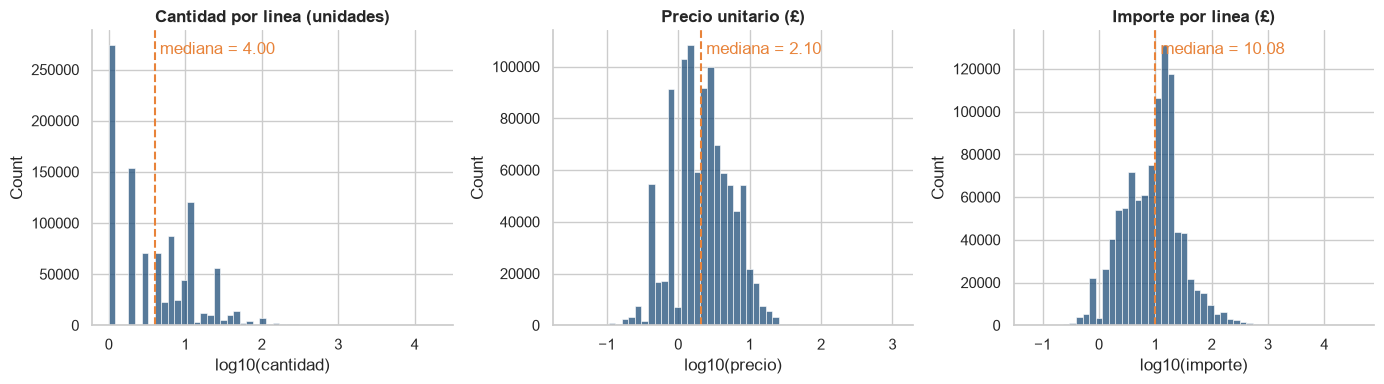

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, tit in zip(axs, ['cantidad', 'precio', 'importe'],
                        ['Cantidad por linea (unidades)', 'Precio unitario (£)', 'Importe por linea (£)']):
    sns.histplot(np.log10(ventas[col]), bins=50, color=AZUL, ax=ax)
    ax.set_xlabel(f'log10({col})'); ax.set_title(tit)
    mediana = np.log10(ventas[col].median())
    ax.axvline(mediana, color=NARANJA, ls='--')
    ax.text(mediana, ax.get_ylim()[1] * .92, f' mediana = {ventas[col].median():,.2f}', color=NARANJA)
plt.tight_layout()
plt.savefig(FIG / '03_distribuciones_numericas.png', dpi=150, bbox_inches='tight')
plt.show()

**Qué muestran las tres distribuciones:**
- Las tres variables tienen **colas larguísimas** (asimetría de 41 a 161): la mediana de una línea es de **4 unidades, £2,10 de precio y £10 de importe**, pero el máximo llega a 19.152 unidades y £38.970.
- Por eso en el resto del proyecto se reportan **medianas** además de promedios y se usan **escalas logarítmicas**: el promedio (£19 por línea) es casi el doble de la mediana (£10).
- En escala log `precio` e `importe` se ven casi simétricos, lo que justifica trabajar con el logaritmo en las pruebas de hipótesis. `cantidad` sigue concentrada en valores bajos (muchas líneas de 1 a 3 unidades, porque son enteros), pero con una cola mucho más corta que en escala normal.

## 2. A nivel de pedido

Un pedido es la unidad con la que el negocio piensa (ticket, devoluciones, recompra). Se resumen sus tres magnitudes: líneas por pedido, unidades y valor.

In [5]:
pedidos[['lineas', 'productos', 'unidades', 'importe']].describe(percentiles=[.5, .9, .99]).T

,count,mean,std,min,50%,90%,99%,max
lineas,"39,514.00",25.39,42.62,1.00,15.00,52.00,198.00,"1,113.00"
productos,"39,514.00",25.11,42.28,1.00,15.00,51.00,196.87,"1,109.00"
unidades,"39,514.00",279.22,"1,070.74",1.00,148.00,523.00,"2,223.61","87,167.00"
importe,"39,514.00",490.96,"1,126.90",0.19,301.21,905.49,"4,097.99","52,940.94"


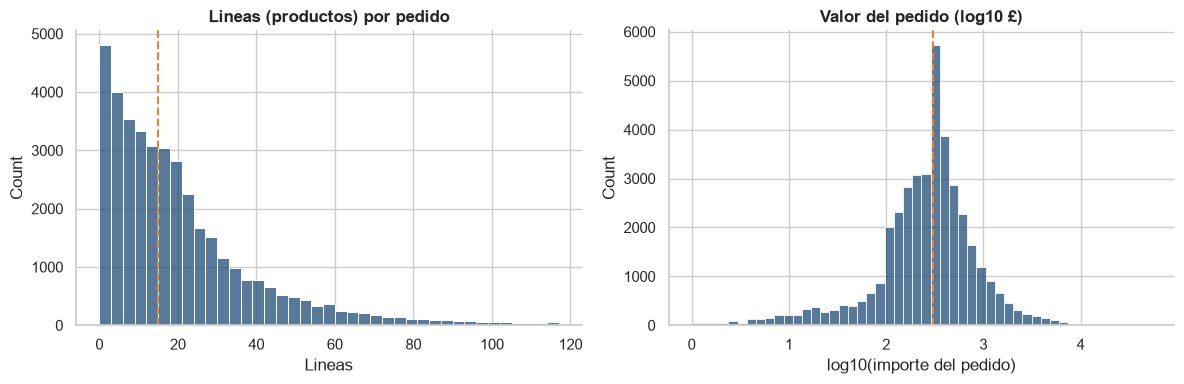

Pedido mediano: 15 lineas y £301  |  pedido promedio: £491


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(pedidos['lineas'], bins=range(0, 120, 3), color=AZUL, ax=axs[0])
axs[0].set_title('Lineas (productos) por pedido'); axs[0].set_xlabel('Lineas')
sns.histplot(np.log10(pedidos['importe'].clip(lower=1)), bins=50, color=AZUL, ax=axs[1])
axs[1].set_title('Valor del pedido (log10 £)'); axs[1].set_xlabel('log10(importe del pedido)')
for ax, v in zip(axs, [pedidos['lineas'].median(), np.log10(pedidos['importe'].median())]):
    ax.axvline(v, color=NARANJA, ls='--')
plt.tight_layout()
plt.show()
print(f'Pedido mediano: {pedidos["lineas"].median():.0f} lineas y £{pedidos["importe"].median():,.0f}  |  pedido promedio: £{pedidos["importe"].mean():,.0f}')

**El pedido típico** tiene 15 líneas y vale **£301** (mediana). El promedio es **£491**: unos pocos pedidos grandes (el 1 % más grande pasa de £4.098) jalan el promedio hacia arriba. Esto confirma que en este negocio **el promedio engaña**: para hablar de un pedido "típico" hay que usar la mediana.

## 3. Variables categóricas: países y productos

Reino Unido concentra 85.3% de las ventas brutas


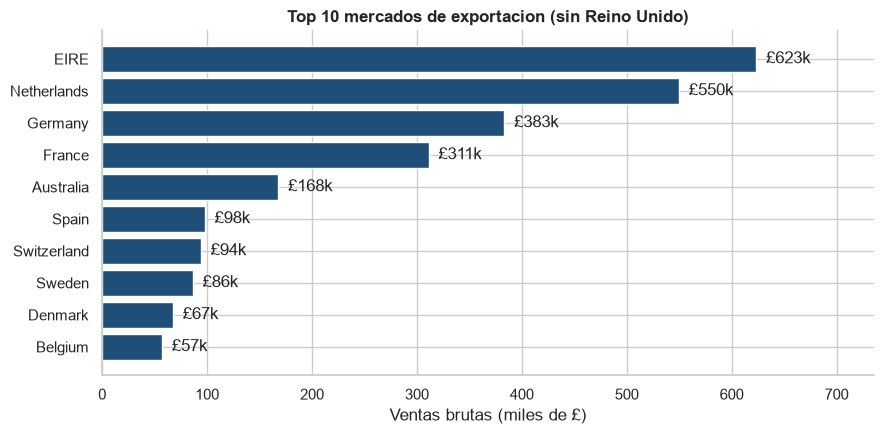

In [7]:
por_pais = (ventas.groupby('pais')['importe'].sum().sort_values(ascending=False))
uk_share = por_pais['United Kingdom'] / por_pais.sum()
print(f'Reino Unido concentra {uk_share:.1%} de las ventas brutas')

fig, ax = plt.subplots(figsize=(9, 4.5))
top = por_pais.drop('United Kingdom').head(10)[::-1]
ax.barh(top.index, top.values / 1000, color=AZUL)
for i, v in enumerate(top.values / 1000):
    ax.text(v, i, f'  £{v:,.0f}k', va='center')
ax.set_title('Top 10 mercados de exportacion (sin Reino Unido)')
ax.set_xlabel('Ventas brutas (miles de £)')
ax.set_xlim(0, top.max() / 1000 * 1.18)
plt.tight_layout()
plt.savefig(FIG / '03_top_paises_exterior.png', dpi=150, bbox_inches='tight')
plt.show()

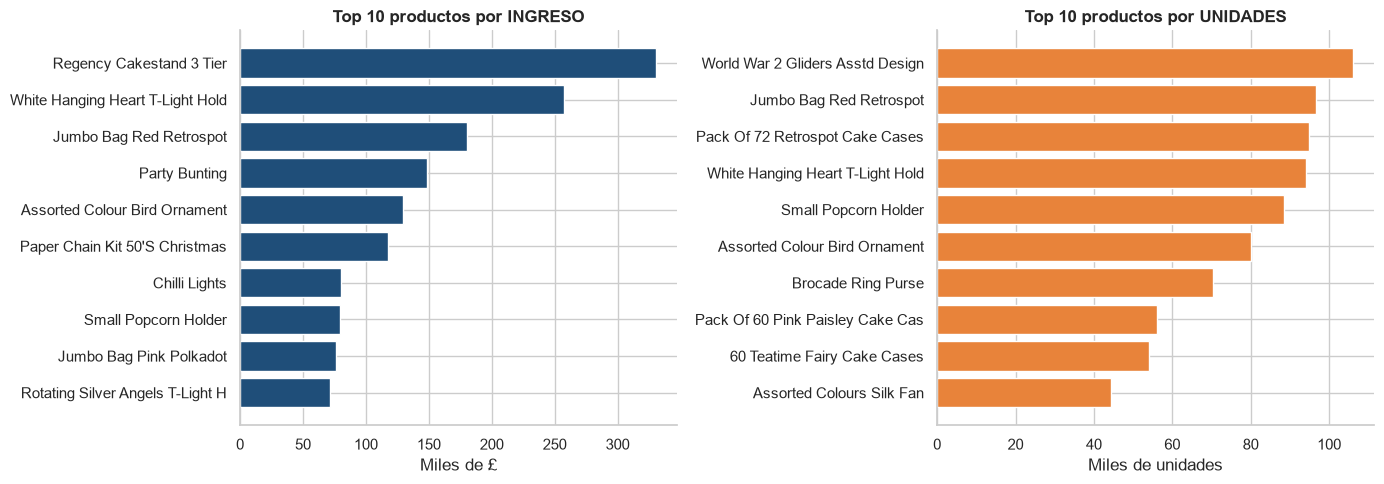

Productos en comun entre ambos rankings: 4


In [8]:
prod = ventas.groupby(['codigo', 'descripcion']).agg(ingreso=('importe', 'sum'), unidades=('cantidad', 'sum')).reset_index()

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
t1 = prod.nlargest(10, 'ingreso')[::-1]
axs[0].barh(t1['descripcion'].str.title().str[:32], t1['ingreso'] / 1000, color=AZUL)
axs[0].set_title('Top 10 productos por INGRESO'); axs[0].set_xlabel('Miles de £')
t2 = prod.nlargest(10, 'unidades')[::-1]
axs[1].barh(t2['descripcion'].str.title().str[:32], t2['unidades'] / 1000, color=NARANJA)
axs[1].set_title('Top 10 productos por UNIDADES'); axs[1].set_xlabel('Miles de unidades')
plt.tight_layout()
plt.savefig(FIG / '03_top_productos.png', dpi=150, bbox_inches='tight')
plt.show()
print('Productos en comun entre ambos rankings:', len(set(t1['codigo']) & set(t2['codigo'])))

**Países.** El **Reino Unido concentra el 85 % de las ventas**; el resto del mundo es un mercado pequeño pero diverso. Entre los mercados de exportación lideran EIRE, Países Bajos, Alemania y Francia.

**Productos.** El producto que más ingresos deja (Regency Cakestand 3 Tier) **no es el que más unidades vende** (World War 2 Gliders, que cuesta muy poco). Solo **4 de los 10 productos coinciden** entre ambos rankings: ordenar el catálogo por unidades o por ingresos lleva a decisiones de inventario diferentes, y conviene mirar ambos.

## 4. Patrones temporales (P1)

Se excluye **diciembre de 2011** porque los datos terminan el día 9 (compararlo con un diciembre completo sería engañoso).

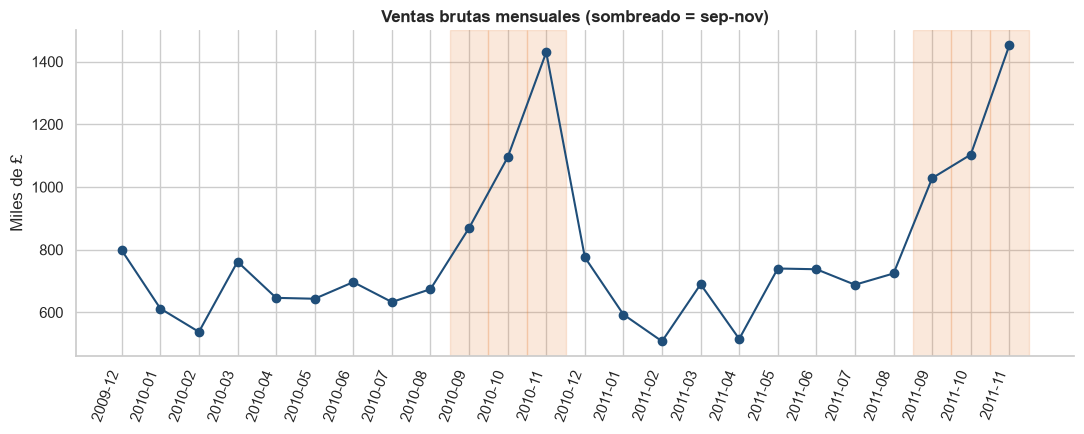

In [9]:
completo = ventas[~ventas['mes_incompleto']]
mensual = completo.groupby('anio_mes')['importe'].sum()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(mensual.index, mensual.values / 1000, marker='o', color=AZUL)
for i, m in enumerate(mensual.index):
    if int(m[5:]) in (9, 10, 11):
        ax.axvspan(i - .5, i + .5, color=NARANJA, alpha=.18)
ax.set_xticks(range(len(mensual)))
ax.set_xticklabels(mensual.index, rotation=70, ha='right')
ax.set_title('Ventas brutas mensuales (sombreado = sep-nov)')
ax.set_ylabel('Miles de £')
plt.tight_layout()
plt.savefig(FIG / '03_ventas_mensuales.png', dpi=150, bbox_inches='tight')
plt.show()

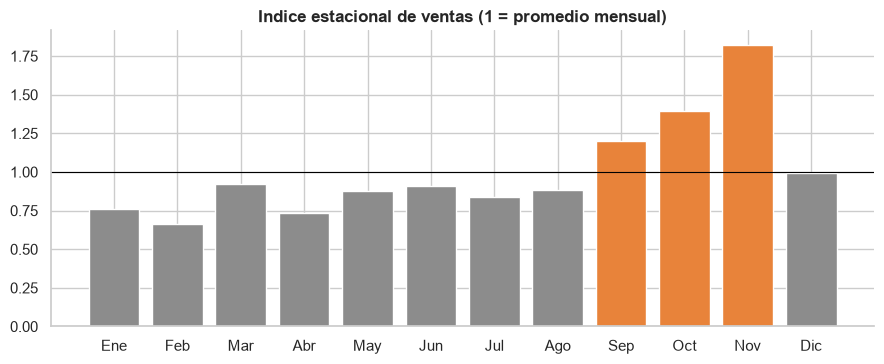

mes,1,2,3,4,5,6,7,8,9,10,11,12
indice,0.76,0.66,0.92,0.74,0.88,0.91,0.84,0.89,1.20,1.39,1.82,1.00


In [10]:
# Indice estacional: promedio del mes calendario / promedio mensual global (solo meses completos)
mensual_df = mensual.reset_index()
mensual_df['mes'] = mensual_df['anio_mes'].str[5:].astype(int)
indice = mensual_df.groupby('mes')['importe'].mean() / mensual_df['importe'].mean()

fig, ax = plt.subplots(figsize=(9, 3.8))
colores = [NARANJA if v > 1.15 else GRIS for v in indice.values]
ax.bar(indice.index, indice.values, color=colores)
ax.axhline(1, color='black', lw=.8)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic'])
ax.set_title('Indice estacional de ventas (1 = promedio mensual)')
plt.tight_layout()
plt.savefig(FIG / '03_indice_estacional.png', dpi=150, bbox_inches='tight')
plt.show()
indice.round(2).to_frame('indice').T

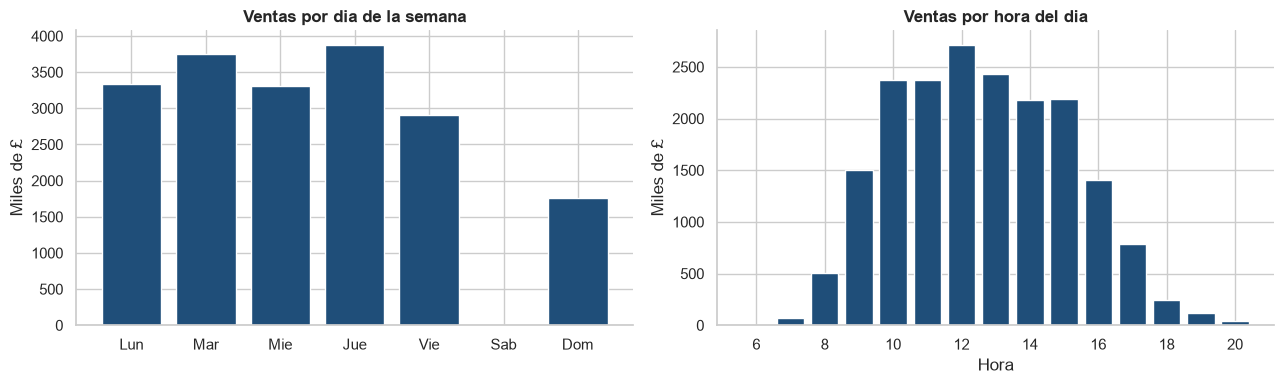

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
dias = ['Lun', 'Mar', 'Mie', 'Jue', 'Vie', 'Sab', 'Dom']
por_dia = completo.groupby('dia_semana')['importe'].sum().reindex(range(7), fill_value=0)
axs[0].bar([dias[i] for i in por_dia.index], por_dia.values / 1000, color=AZUL)
axs[0].set_title('Ventas por dia de la semana'); axs[0].set_ylabel('Miles de £')
por_hora = completo.groupby('hora')['importe'].sum()
axs[1].bar(por_hora.index, por_hora.values / 1000, color=AZUL)
axs[1].set_title('Ventas por hora del dia'); axs[1].set_xlabel('Hora'); axs[1].set_ylabel('Miles de £')
plt.tight_layout()
plt.show()

**Estacionalidad (P1).**
- Las ventas mensuales tienen un patrón claro y repetido en 2010 y 2011: **suben desde septiembre y alcanzan su máximo en noviembre**, y caen en enero–febrero.
- El índice estacional lo cuantifica: septiembre = **1,20**, octubre = **1,39**, noviembre = **1,82** veces el mes promedio, frente a 0,66–1,00 en el resto de meses. De aquí sale la definición de **temporada alta = septiembre–noviembre** que usan la hipótesis H1 y el dashboard.
- **Día y hora:** el **jueves** es el día más fuerte (20,5 % de las ventas); el viernes es el más flojo entre semana; el **sábado prácticamente no hay ventas** (0,05 %) y el domingo sí (~9 %). Cerca del **75 % de las ventas ocurre entre las 10:00 y las 15:59**, con pico a las 12:00. Es el patrón de un cliente que compra en horario de oficina: negocios que reponen inventario.

## 5. Análisis multivariado

Aquí se buscan **relaciones entre varias variables a la vez**: qué se mueve junto, qué se concentra y qué cambia según el segmento.

### 5.1 Correlaciones entre magnitudes del pedido
Se usa **Spearman** (basada en rangos) porque las variables tienen colas muy largas y Pearson sería dominado por unos pocos pedidos enormes.

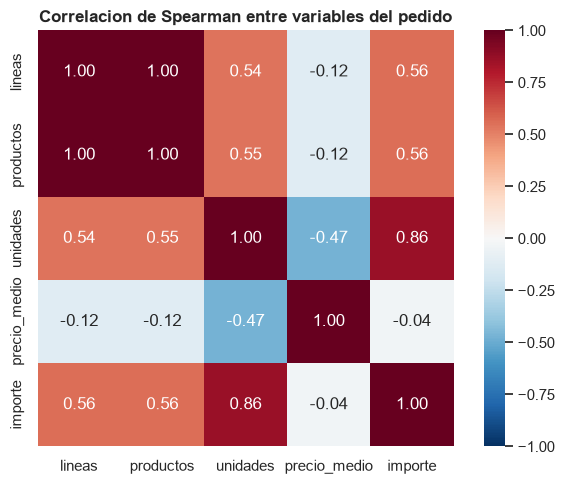

In [12]:
cols = ['lineas', 'productos', 'unidades', 'precio_medio', 'importe']
corr = pedidos[cols].corr(method='spearman')
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title('Correlacion de Spearman entre variables del pedido')
plt.tight_layout()
plt.savefig(FIG / '03_correlacion_pedido.png', dpi=150, bbox_inches='tight')
plt.show()

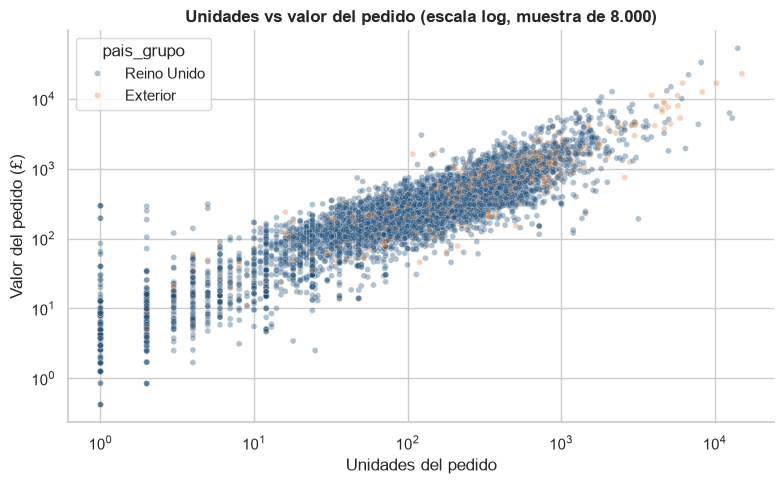

In [13]:
muestra = pedidos.sample(8000, random_state=42)
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=muestra, x='unidades', y='importe', hue='pais_grupo', alpha=.35, s=18,
                palette={'Reino Unido': AZUL, 'Exterior': NARANJA}, ax=ax)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_title('Unidades vs valor del pedido (escala log, muestra de 8.000)')
ax.set_xlabel('Unidades del pedido'); ax.set_ylabel('Valor del pedido (£)')
plt.tight_layout()
plt.show()

**Qué se mueve junto (Spearman):**
- `lineas` y `productos` tienen correlación **1,00**: cada línea es un producto distinto (no se repite el producto dentro de un pedido).
- El valor del pedido depende sobre todo de las **unidades** (ρ = 0,86) y menos del número de líneas (ρ = 0,56). Un pedido vale más porque se compran **más unidades por producto**, no porque se compren más productos distintos.
- El **precio medio baja cuando suben las unidades** (ρ = −0,47): señal de **precios por volumen** típicos del mayorista.
- En el gráfico de dispersión log-log la relación unidades–valor es casi lineal: duplicar las unidades duplica aproximadamente el valor del pedido.

### 5.2 ¿Cuándo se compra? Día de la semana × hora

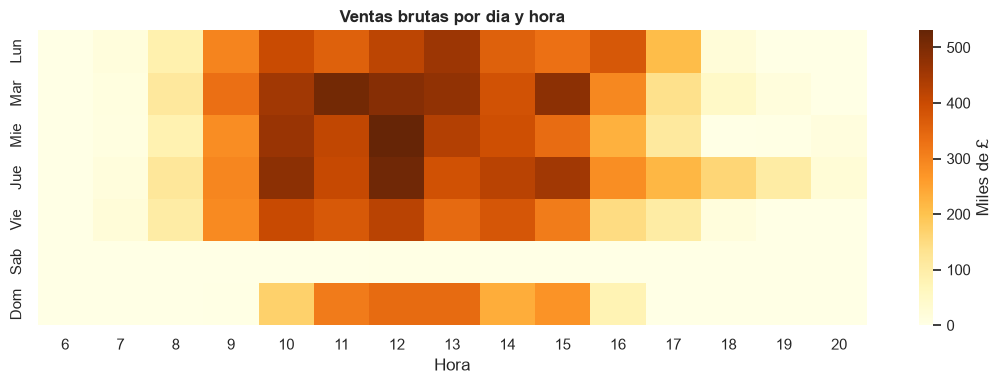

Sabado: 0.05% de las ventas | Jueves: 20.5%


In [14]:
mapa = (completo.pivot_table(index='dia_semana', columns='hora', values='importe', aggfunc='sum')
        .reindex(range(7)).fillna(0) / 1000)
mapa.index = ['Lun', 'Mar', 'Mie', 'Jue', 'Vie', 'Sab', 'Dom']
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(mapa, cmap='YlOrBr', cbar_kws={'label': 'Miles de £'}, ax=ax)
ax.set_title('Ventas brutas por dia y hora'); ax.set_xlabel('Hora'); ax.set_ylabel('')
plt.tight_layout()
plt.savefig(FIG / '03_mapa_dia_hora.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Sabado: {mapa.loc["Sab"].sum() / mapa.sum().sum():.2%} de las ventas | Jueves: {mapa.loc["Jue"].sum() / mapa.sum().sum():.1%}')

### 5.3 Ticket por mercado
¿El tamaño del pedido cambia según el país? Se usan **medianas** (robustas a pedidos gigantes) y se muestra el número de pedidos para no sobreinterpretar países pequeños.

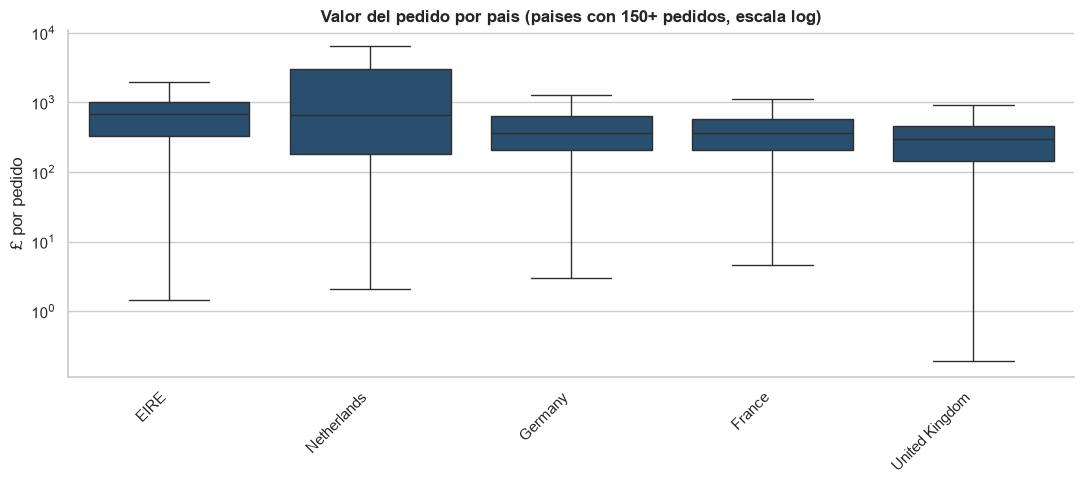

,pedidos,mediana,promedio
pais,,,
EIRE,581,693.62,"1,073.00"
Netherlands,216,657.08,"2,545.25"
Germany,753,360.30,509.02
France,598,360.06,520.22
United Kingdom,36182,295.07,457.61


In [15]:
n_ped = pedidos.groupby('pais').size()
top_paises = n_ped[n_ped >= 150].index
tk = pedidos[pedidos['pais'].isin(top_paises)]
orden = tk.groupby('pais')['importe'].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=tk, x='pais', y='importe', order=orden, color=AZUL, showfliers=False, ax=ax)
ax.set_yscale('log')
ax.set_title('Valor del pedido por pais (paises con 150+ pedidos, escala log)')
ax.set_xlabel(''); ax.set_ylabel('£ por pedido')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(FIG / '03_ticket_por_pais.png', dpi=150, bbox_inches='tight')
plt.show()
resumen_pais = (tk.groupby('pais')['importe'].agg(pedidos='size', mediana='median', promedio='mean')
                .sort_values('mediana', ascending=False))
resumen_pais.head(8)

### 5.4 Concentración del ingreso (Pareto) — P2

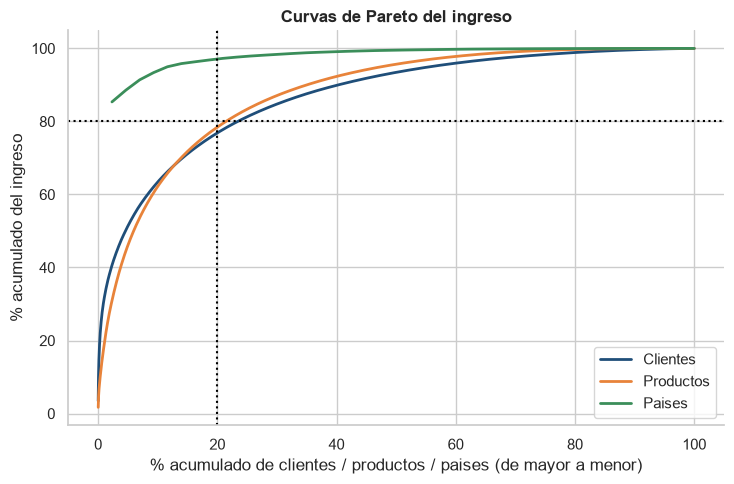

El 20% de clientes (1,170) concentra 76.9% del ingreso
El 20% de productos (980) concentra 78.4% del ingreso
El 20% de paises (9) concentra 97.3% del ingreso


In [16]:
def curva_pareto(serie):
    s = serie.sort_values(ascending=False).values
    acum = np.cumsum(s) / s.sum()
    x = np.arange(1, len(s) + 1) / len(s)
    return x, acum

ing_cliente = ventas.dropna(subset=['cliente_id']).groupby('cliente_id')['importe'].sum()
ing_producto = ventas.groupby('codigo')['importe'].sum()
ing_pais = ventas.groupby('pais')['importe'].sum()

fig, ax = plt.subplots(figsize=(7.5, 5))
for serie, nombre, color in [(ing_cliente, 'Clientes', AZUL), (ing_producto, 'Productos', NARANJA), (ing_pais, 'Paises', VERDE)]:
    x, y = curva_pareto(serie)
    ax.plot(x * 100, y * 100, label=nombre, color=color, lw=2)
ax.axvline(20, color='black', ls=':'); ax.axhline(80, color='black', ls=':')
ax.set_xlabel('% acumulado de clientes / productos / paises (de mayor a menor)')
ax.set_ylabel('% acumulado del ingreso')
ax.set_title('Curvas de Pareto del ingreso')
ax.legend()
plt.tight_layout()
plt.savefig(FIG / '03_pareto.png', dpi=150, bbox_inches='tight')
plt.show()

for serie, nombre in [(ing_cliente, 'clientes'), (ing_producto, 'productos'), (ing_pais, 'paises')]:
    k = max(1, int(round(len(serie) * .2)))
    print(f'El 20% de {nombre} ({k:,}) concentra {serie.nlargest(k).sum() / serie.sum():.1%} del ingreso')

**Ticket por mercado.** Entre los países con 150+ pedidos, **EIRE (£694) y Países Bajos (£657) tienen la mediana de pedido más alta**, más del doble que el Reino Unido (£295). Alemania y Francia están en £360. Los países pequeños (menos de 150 pedidos) no se grafican para no sacar conclusiones con pocos datos. Esto da pie a H2.

**Concentración (P2) — la regla 80/20 se cumple:**
- El 20 % de los **clientes** (1.170) concentra el **76,9 %** del ingreso.
- El 20 % de los **productos** (980) concentra el **78,4 %**.
- El 20 % de los **países** (9) concentra el **97,3 %**.

La dependencia de pocos clientes es el principal riesgo de negocio: perder a unos cuantos mayoristas grandes mueve el ingreso total.

## 6. Clientes: segmentación RFM y cohortes (P3)

**RFM** resume a cada cliente en tres números: **R**ecencia (días desde su última compra), **F**recuencia (número de pedidos) y **M**onetario (ventas brutas). Se agrupan con **KMeans** sobre las variables transformadas (log + estandarizadas) para que los extremos no dominen.

Solo se usan clientes **identificados** (los invitados no tienen historial).

In [17]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

fecha_ref = ventas['fecha'].max() + pd.Timedelta(days=1)
cli = ventas.dropna(subset=['cliente_id'])
rfm = (cli.groupby('cliente_id')
       .agg(ultima_compra=('fecha', 'max'), primera_compra=('fecha', 'min'),
            frecuencia=('factura', 'nunique'), monetario=('importe', 'sum'))
       .reset_index())
rfm['recencia'] = (fecha_ref - rfm['ultima_compra']).dt.days
rfm = rfm[rfm['monetario'] > 0]
print(f'{len(rfm):,} clientes con historial | referencia: {fecha_ref.date()}')
rfm[['recencia', 'frecuencia', 'monetario']].describe().T

5,852 clientes con historial | referencia: 2011-12-10


,count,mean,std,min,25%,50%,75%,max
recencia,"5,852.00",200.80,208.54,1.00,26.00,96.00,380.00,739.00
frecuencia,"5,852.00",6.25,12.75,1.00,1.00,3.00,7.00,373.00
monetario,"5,852.00","2,874.73","14,108.71",2.90,339.24,855.58,"2,237.29","580,987.04"


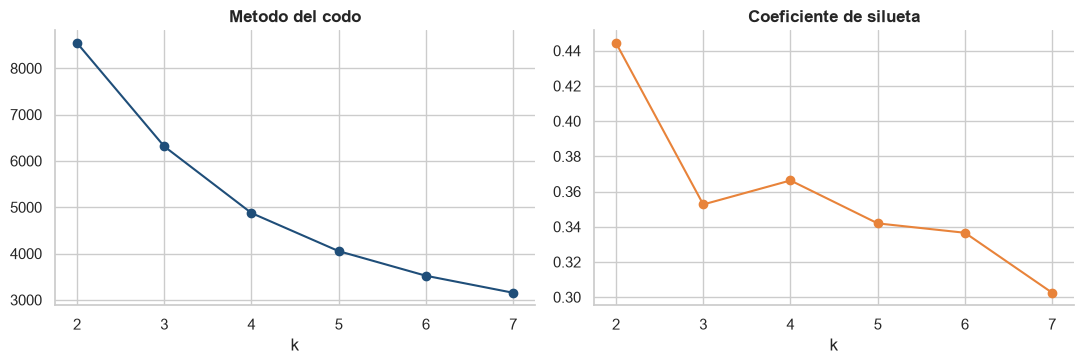

,k,inercia,silueta
0,2,"8,545.66",0.44
1,3,"6,313.00",0.35
2,4,"4,874.27",0.37
3,5,"4,052.05",0.34
4,6,"3,520.81",0.34
5,7,"3,153.49",0.30


In [18]:
X = np.log1p(rfm[['recencia', 'frecuencia', 'monetario']])
Xs = StandardScaler().fit_transform(X)

# Eleccion de k: inercia (codo) y silueta
resultados = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    sil = silhouette_score(Xs, km.labels_, sample_size=3000, random_state=42)
    resultados.append((k, km.inertia_, sil))
res = pd.DataFrame(resultados, columns=['k', 'inercia', 'silueta'])

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(res['k'], res['inercia'], marker='o', color=AZUL); axs[0].set_title('Metodo del codo'); axs[0].set_xlabel('k')
axs[1].plot(res['k'], res['silueta'], marker='o', color=NARANJA); axs[1].set_title('Coeficiente de silueta'); axs[1].set_xlabel('k')
plt.tight_layout()
plt.show()
res

In [19]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xs)
rfm['cluster'] = km.labels_

# Los nombres se asignan por PERFIL (no por el numero de cluster, que puede cambiar entre ejecuciones)
perfil = rfm.groupby('cluster').agg(clientes=('cliente_id', 'size'), recencia=('recencia', 'median'),
                                    frecuencia=('frecuencia', 'median'), monetario=('monetario', 'median'))
mapa_nombres = {}
mapa_nombres[perfil['monetario'].idxmax()] = 'Campeones'        # los que mas gastan
resto = perfil.drop(index=list(mapa_nombres))
mapa_nombres[resto['recencia'].idxmax()] = 'Dormidos'          # los que llevan mas tiempo sin comprar
resto = perfil.drop(index=list(mapa_nombres))
mapa_nombres[resto['recencia'].idxmax()] = 'En riesgo'         # de los 2 restantes, el menos reciente
mapa_nombres[resto['recencia'].idxmin()] = 'Recientes'         # y el mas reciente
rfm['segmento'] = rfm['cluster'].map(mapa_nombres)

perfil['segmento'] = perfil.index.map(mapa_nombres)
perfil['% ingreso'] = rfm.groupby('cluster')['monetario'].sum() / rfm['monetario'].sum() * 100
perfil.set_index('segmento').sort_values('monetario', ascending=False)

,clientes,recencia,frecuencia,monetario,% ingreso
segmento,,,,,
Campeones,1190,17.00,13.00,"4,889.43",73.58
En riesgo,1446,185.00,4.00,"1,449.59",16.47
Recientes,1260,24.00,3.00,716.46,6.27
Dormidos,1956,402.00,1.00,273.32,3.67


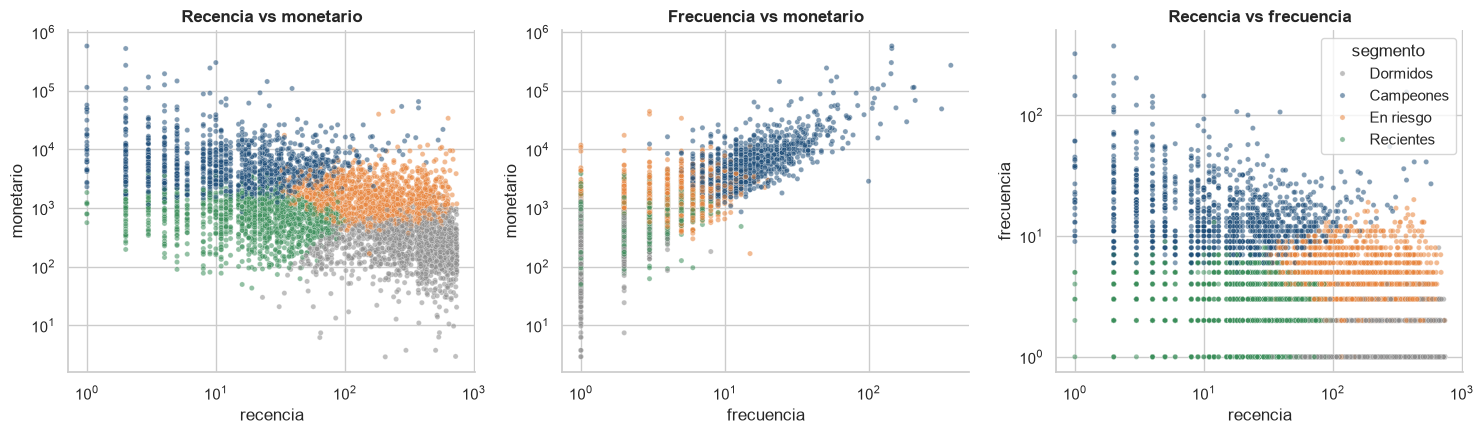

Correlacion de Spearman entre R, F y M:


,recencia,frecuencia,monetario
recencia,1.00,-0.56,-0.51
frecuencia,-0.56,1.00,0.86
monetario,-0.51,0.86,1.00


In [20]:
paleta = {'Campeones': AZUL, 'Recientes': VERDE, 'En riesgo': NARANJA, 'Dormidos': GRIS}
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
pares = [('recencia', 'monetario'), ('frecuencia', 'monetario'), ('recencia', 'frecuencia')]
for ax, (a, b) in zip(axs, pares):
    sns.scatterplot(data=rfm, x=a, y=b, hue='segmento', palette=paleta, alpha=.55, s=14, ax=ax, legend=(a == 'recencia' and b == 'frecuencia'))
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_title(f'{a.capitalize()} vs {b}')
plt.tight_layout()
plt.savefig(FIG / '03_rfm_segmentos.png', dpi=150, bbox_inches='tight')
plt.show()

print('Correlacion de Spearman entre R, F y M:')
rfm[['recencia', 'frecuencia', 'monetario']].corr(method='spearman').round(2)

**Elección de k.** La silueta es mayor con k = 2 (0,44), pero solo separaría "activos" de "inactivos". Se elige **k = 4** porque tiene un máximo local (0,37, mayor que k = 3 y k = 5) y produce grupos **accionables**. Es una decisión de negocio, no solo estadística.

| Segmento | Clientes | % del ingreso | Perfil (medianas) | Acción sugerida |
|---|---|---|---|---|
| **Campeones** | 1.190 (20 %) | **73,6 %** | compraron hace 17 días, 13 pedidos, £4.889 | Cuidarlos: gestor de cuenta, crédito, prioridad de stock |
| **En riesgo** | 1.446 (25 %) | 16,5 % | hace 185 días, 4 pedidos, £1.450 | Reactivar: ofertas personalizadas antes de que se pierdan |
| **Recientes** | 1.260 (22 %) | 6,3 % | hace 24 días, 3 pedidos, £716 | Fidelizar: llevarlos a un 2.º y 3.er pedido |
| **Dormidos** | 1.956 (33 %) | 3,7 % | hace 402 días, 1 pedido, £273 | Bajo costo: campañas masivas automáticas |

Las tres variables están relacionadas, pero no son redundantes: **frecuencia y monto se mueven juntas** (ρ = 0,86) y **recencia se relaciona negativamente con ambas** (ρ ≈ −0,5): quien compró hace poco compra más seguido y más.

### Cohortes de retención
Cada cliente pertenece a la **cohorte** del mes de su primera compra. Se mide qué porcentaje de la cohorte vuelve a comprar *k* meses después. Así se responde "¿cuántos clientes se quedan?" sin mezclar clientes nuevos con antiguos.

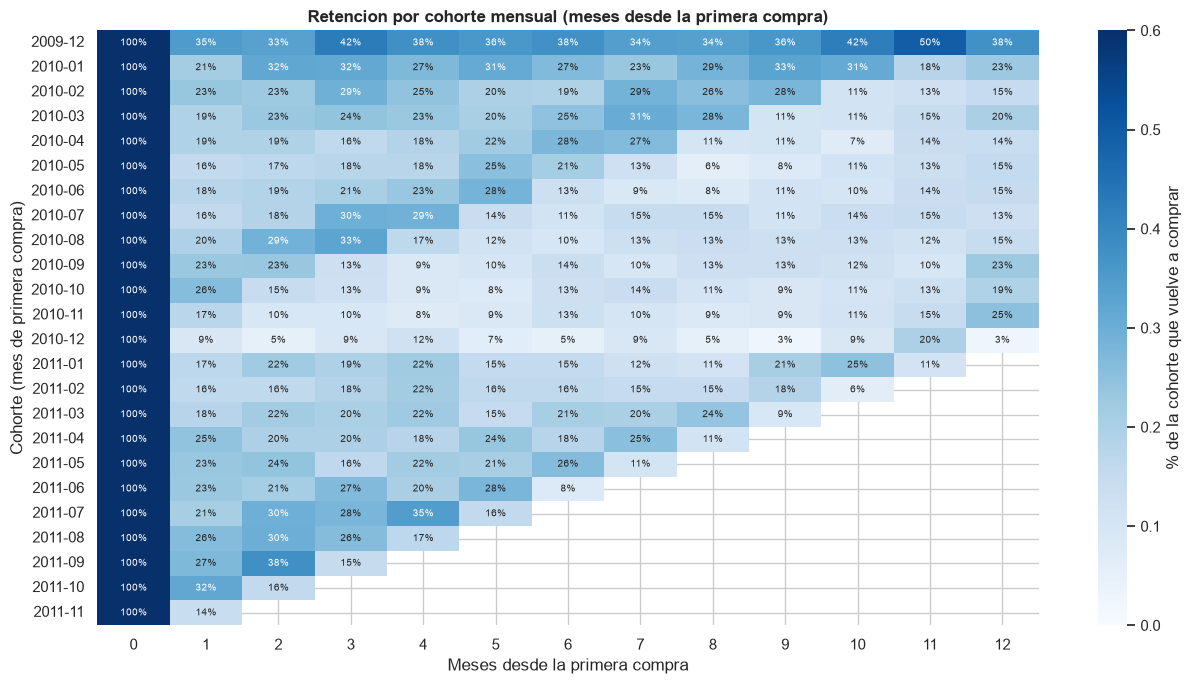

Retencion promedio por mes desde la primera compra (todas las cohortes):


offset,1,2,3,4,5,6
retencion promedio,0.21,0.22,0.22,0.21,0.19,0.18


In [21]:
cli = cli.copy()
cli['mes_compra'] = cli['fecha'].dt.to_period('M')
cli['cohorte'] = cli.groupby('cliente_id')['mes_compra'].transform('min')
cli['offset'] = (cli['mes_compra'] - cli['cohorte']).apply(lambda x: x.n)

act = cli.groupby(['cohorte', 'offset'])['cliente_id'].nunique().unstack()
retencion = act.div(act[0], axis=0)
retencion = retencion[retencion.index < '2011-12']     # cohorte de dic-2011 incompleta
retencion.index = retencion.index.astype(str)

fig, ax = plt.subplots(figsize=(13, 7))
sns.heatmap(retencion.iloc[:, :13], annot=True, fmt='.0%', cmap='Blues', vmin=0, vmax=.6,
            cbar_kws={'label': '% de la cohorte que vuelve a comprar'}, annot_kws={'size': 7}, ax=ax)
ax.set_title('Retencion por cohorte mensual (meses desde la primera compra)')
ax.set_xlabel('Meses desde la primera compra'); ax.set_ylabel('Cohorte (mes de primera compra)')
plt.tight_layout()
plt.savefig(FIG / '03_cohortes_retencion.png', dpi=150, bbox_inches='tight')
plt.show()
print('Retencion promedio por mes desde la primera compra (todas las cohortes):')
retencion.iloc[:, 1:7].mean().round(3).to_frame('retencion promedio').T

In [22]:
# Guardar para el modelo (notebook 05) y el dashboard
salida = rfm[['cliente_id', 'primera_compra', 'ultima_compra', 'recencia', 'frecuencia', 'monetario', 'segmento']].copy()
salida['cliente_id'] = salida['cliente_id'].astype('Int64')
salida.to_parquet(PROC / 'rfm_clientes.parquet', index=False)
print(f'Guardado rfm_clientes.parquet ({len(salida):,} clientes)')
salida['segmento'].value_counts().to_frame('clientes')

Guardado rfm_clientes.parquet (5,852 clientes)


,clientes
segmento,
Dormidos,1956
En riesgo,1446
Recientes,1260
Campeones,1190


**Retención (P3).**
- En promedio, **~21 % de una cohorte vuelve a comprar cada mes** durante los primeros 6 meses (18–22 %).
- La **cohorte de diciembre de 2009 retiene 33–50 %**, muy por encima del resto. No significa que fuera "mejor": al ser el primer mes de los datos, **incluye a clientes antiguos que ya compraban** (efecto de censura a la izquierda). Se interpreta con cautela.
- Las cohortes de **septiembre a noviembre de 2010** retienen **menos (~8–14 % en los meses 3–6)** que las de mediados de año. Es una pista: los clientes captados en temporada alta compran en la campaña y no vuelven. **H5 pone a prueba esta idea.**
- Las cohortes de 2011 se mantienen en ~15–25 % mensual.